In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Python environment is working!")
print("Pandas version:", pd.__version__)
print("Matplotlib and Seaborn imported successfully!")

Python environment is working!
Pandas version: 2.1.4
Matplotlib and Seaborn imported successfully!


# Exploratory Data Analysis on Retail Sales Data

## 1. Introduction

This project performs Exploratory Data Analysis (EDA) on an Indian e-commerce dataset to understand sales patterns, customer behaviour, product performance, and business trends.

The analysis uses customer, product, order, and order-item datasets to identify meaningful patterns and generate actionable business recommendations.

## 2. Objectives

- Inspect the datasets and identify missing values.
- Calculate descriptive statistics for numerical variables.
- Analyse monthly and quarterly sales trends.
- Explore customer demographics.
- Identify top-selling products and revenue by category.
- Examine correlations between numerical variables.
- Discover additional insights through visualisations.
- Provide actionable business recommendations.

## 3. Libraries Used

- Pandas
- Matplotlib
- Seaborn
- NumPy

## 4. Dataset

The project uses four main CSV files: customers, products, orders, and order items. A data dictionary is also included to understand the dataset columns.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualisation style
sns.set_style("whitegrid")

# Load the datasets
customers = pd.read_csv("dataset/customers.csv")
products = pd.read_csv("dataset/products.csv")
orders = pd.read_csv("dataset/orders.csv")
order_items = pd.read_csv("dataset/order_items.csv")
data_dictionary = pd.read_csv("dataset/data_dictionary.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [3]:
# Store datasets for easy inspection
datasets = {
    "Customers": customers,
    "Products": products,
    "Orders": orders,
    "Order Items": order_items,
    "Data Dictionary": data_dictionary
}

# Inspect each dataset
for name, df in datasets.items():
    print("\n", "=" * 50)
    print(name)
    print("=" * 50)

    print("\nDataset Shape:", df.shape)

    print("\nColumn Data Types:")
    print(df.dtypes)

    print("\nMissing Values:")
    print(df.isnull().sum()[df.isnull().sum() > 0])


Customers

Dataset Shape: (25000, 18)

Column Data Types:
customer_id                  object
customer_signup_date         object
gender                       object
age                         float64
age_group                    object
state                        object
city                         object
pincode_prefix                int64
customer_segment             object
preferred_device             object
preferred_payment_method     object
acquisition_channel          object
total_orders                  int64
total_spend                 float64
last_order_date              object
average_order_value         float64
customer_status              object
loyalty_tier                 object
dtype: object

Missing Values:
age                  250
preferred_device     125
last_order_date     2300
dtype: int64

Products

Dataset Shape: (550, 14)

Column Data Types:
product_id               object
product_name             object
category                 object
subcategory           

### Observations – Initial Dataset Inspection

1. The customers dataset contains 25,000 records and 18 columns, with missing values in age, preferred_device, and last_order_date.
2. The products dataset contains 550 records and 14 columns. Only rating_average has missing values.
3. The orders dataset contains 100,000 records and 10 columns. The coupon_code column contains missing values, which may indicate orders placed without coupons.
4. The order_items dataset contains 254,331 records and 9 columns, with no missing values.
5. The data dictionary contains 106 entries describing the dataset columns and their business meanings.

The date-related columns are currently stored as object data types and will need conversion before time-series analysis.

Overall, the datasets provide information about customers, products, orders, and individual purchased items, allowing different aspects of retail performance to be examined.

## 5. Descriptive Statistical Analysis

Descriptive statistics are used to understand the distribution and central tendency of numerical variables in the datasets. Mean, median, mode, and standard deviation are calculated for every numerical column.

In [4]:
# Calculate descriptive statistics for all numerical columns

numerical_datasets = {
    "Customers": customers,
    "Products": products,
    "Orders": orders,
    "Order Items": order_items
}

statistics = []

for dataset_name, df in numerical_datasets.items():

    numerical_columns = df.select_dtypes(include=np.number).columns

    for column in numerical_columns:

        statistics.append({
            "Dataset": dataset_name,
            "Column": column,
            "Mean": df[column].mean(),
            "Median": df[column].median(),
            "Mode": df[column].mode().tolist(),
            "Standard Deviation": df[column].std()
        })

descriptive_stats = pd.DataFrame(statistics)

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

display(descriptive_stats.round(2))

,Dataset,Column,Mean,Median,Mode,Standard Deviation
0,Customers,age,31.82,32.00,[18.0],8.52
1,Customers,pincode_prefix,499.50,501.00,[515],231.23
2,Customers,total_orders,3.88,3.00,[2],3.32
3,Customers,total_spend,100031.11,47466.04,[0.0],130582.71
4,Customers,average_order_value,22135.36,14197.18,[0.0],26901.86
5,Products,price,4429.64,1075.00,"[200.0, 330.0]",10207.04
6,Products,cost_price,3531.20,717.18,[100.4],8786.80
7,Products,rating_average,4.01,4.00,[3.9],0.43
8,Products,rating_count,126.94,54.00,[3],237.04
9,Products,stock_quantity,1487.60,1521.00,[2230],859.79


### Observations – Descriptive Statistics

1. The average customer age is 31.82 years, with a median of 32 years, indicating a relatively consistent central age distribution.
2. Customers place an average of 3.88 orders, while the median is 3 orders.
3. Average customer spending is higher than the median spending, suggesting that a smaller group of high-spending customers influences the overall average.
4. Product prices show considerable variation, with a mean of 4429.64 and a median of 1075.00.
5. The average product rating is approximately 4.01, indicating generally positive product ratings.
6. The average quantity per order item is 2.30 units.
7. The average item revenue is 9632.72, while average item profit is 775.74.
8. The standard deviations of customer spending, product prices, and item revenue indicate substantial variation in purchasing and product values.

Note: Pincode prefixes are numerical identifiers rather than continuous measurements, so their descriptive statistics have limited business interpretation.

In [5]:
# Convert order_date into datetime format
orders["order_date"] = pd.to_datetime(orders["order_date"])

# Check date range
print("First Order Date:", orders["order_date"].min())
print("Last Order Date:", orders["order_date"].max())

# Check order status distribution
print("\nOrder Status Distribution:")
print(orders["order_status"].value_counts())

# Check order item revenue
print("\nTotal Order Item Revenue:")
print(order_items["item_revenue"].sum())

First Order Date: 2023-01-01 00:00:00
Last Order Date: 2025-12-31 00:00:00

Order Status Distribution:
order_status
Delivered     80679
Cancelled      8073
Returned       6681
Failed         2880
Processing     1687
Name: count, dtype: int64

Total Order Item Revenue:
2449898974.3500004


## 6. Time Series Analysis

Time series analysis is used to understand how sales change over time. In this section, order data is combined with order-item data to calculate monthly and quarterly gross revenue. Only delivered orders are considered for the main sales trend.

In [10]:
# Filter only delivered orders
delivered_orders = orders[orders["order_status"] == "Delivered"].copy()

# Merge delivered orders with order items
sales_data = pd.merge(
    delivered_orders,
    order_items,
    on="order_id",
    how="inner"
)

# Extract year, month and quarter
sales_data["year"] = sales_data["order_date"].dt.year
sales_data["month"] = sales_data["order_date"].dt.month
sales_data["quarter"] = sales_data["order_date"].dt.quarter

# Create monthly revenue summary
monthly_sales = sales_data.groupby(
    pd.Grouper(key="order_date", freq="M")
)["item_revenue"].sum().reset_index()

# Create quarterly revenue summary
quarterly_sales = sales_data.groupby(
    ["year", "quarter"]
)["item_revenue"].sum().reset_index()

print("Delivered sales records:", len(sales_data))
print("\nMonthly sales:")
display(monthly_sales.head())

print("\nQuarterly sales:")
display(quarterly_sales.head())

print("\nTotal gross revenue from delivered orders:")
print(round(sales_data["item_revenue"].sum(), 2))

Delivered sales records: 205224

Monthly sales:


,order_date,item_revenue
0,2023-01-31,8838803.65
1,2023-02-28,19718359.40
2,2023-03-31,36583089.65
3,2023-04-30,43415895.90
4,2023-05-31,49811536.00



Quarterly sales:


,year,quarter,item_revenue
0,2023,1,6.514025e+07
1,2023,2,1.473244e+08
2,2023,3,1.642900e+08
3,2023,4,1.700388e+08
4,2024,1,1.323920e+08



Total gross revenue from delivered orders:
1984905302.15


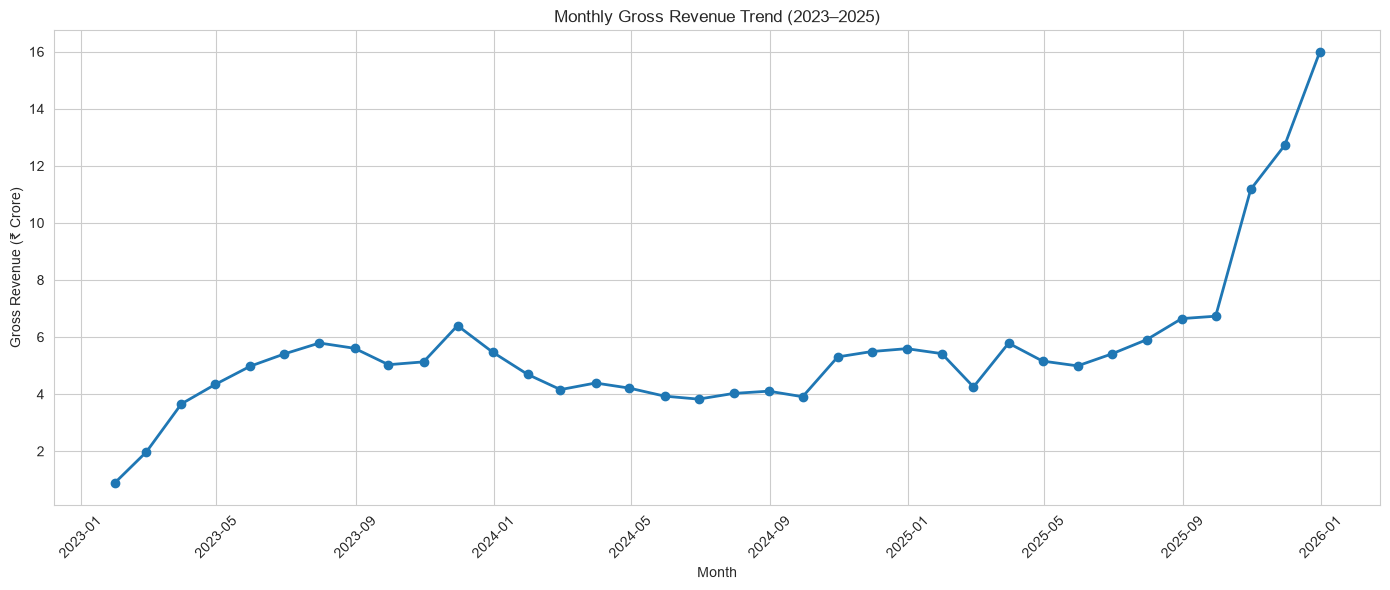

In [11]:
# Monthly Sales Trend

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["order_date"],
    monthly_sales["item_revenue"] / 10000000,
    marker="o",
    linewidth=2
)

plt.title("Monthly Gross Revenue Trend (2023–2025)")
plt.xlabel("Month")
plt.ylabel("Gross Revenue (₹ Crore)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

### Observations from Monthly Sales Trend

- Monthly revenue showed an overall increasing trend during the first half of 2023.
- Revenue fluctuated throughout 2024 and the first half of 2025, remaining relatively stable compared with the initial growth period.
- A significant increase in monthly revenue was observed during the final months of 2025.
- December 2025 recorded the highest monthly gross revenue, reaching approximately ₹16 crore.

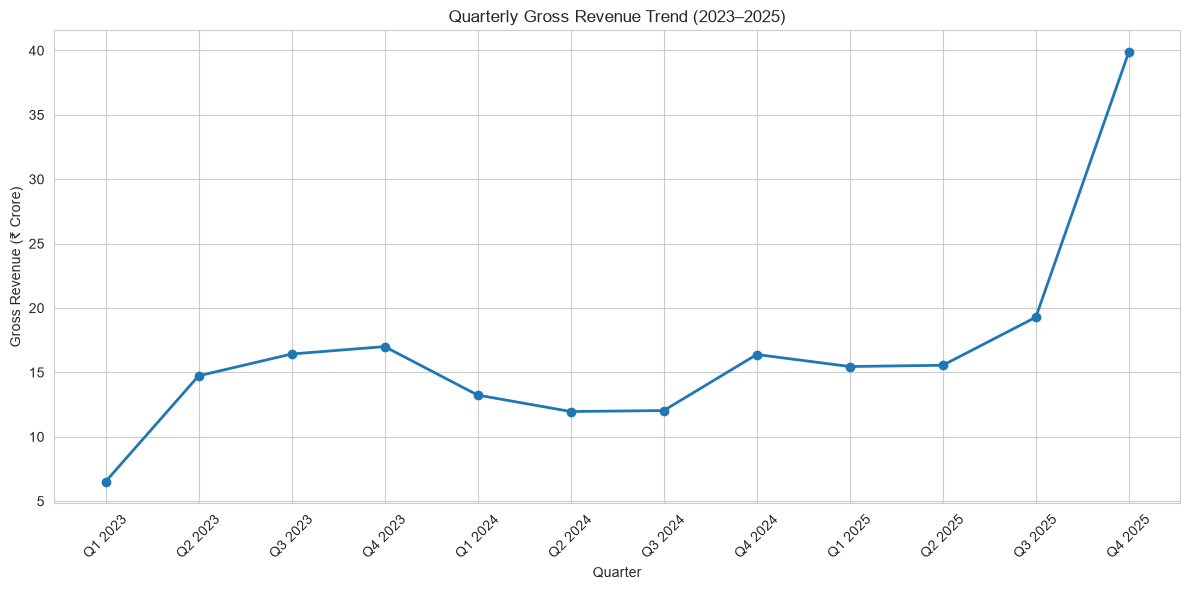

In [12]:
# Create quarter labels
quarterly_sales["quarter_label"] = (
    "Q" + quarterly_sales["quarter"].astype(str)
    + " " + quarterly_sales["year"].astype(str)
)

# Quarterly Sales Trend
plt.figure(figsize=(12, 6))

plt.plot(
    quarterly_sales["quarter_label"],
    quarterly_sales["item_revenue"] / 10000000,
    marker="o",
    linewidth=2
)

plt.title("Quarterly Gross Revenue Trend (2023–2025)")
plt.xlabel("Quarter")
plt.ylabel("Gross Revenue (₹ Crore)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

### Observations from Quarterly Sales Trend

- Q4 2023 recorded the highest quarterly revenue during 2023.
- Quarterly revenue declined during the first three quarters of 2024 before recovering in Q4 2024.
- Revenue showed an increasing trend during the second half of 2025.
- Q4 2025 recorded the highest quarterly gross revenue, reaching approximately ₹40 crore, indicating a substantial increase in sales during the final quarter.

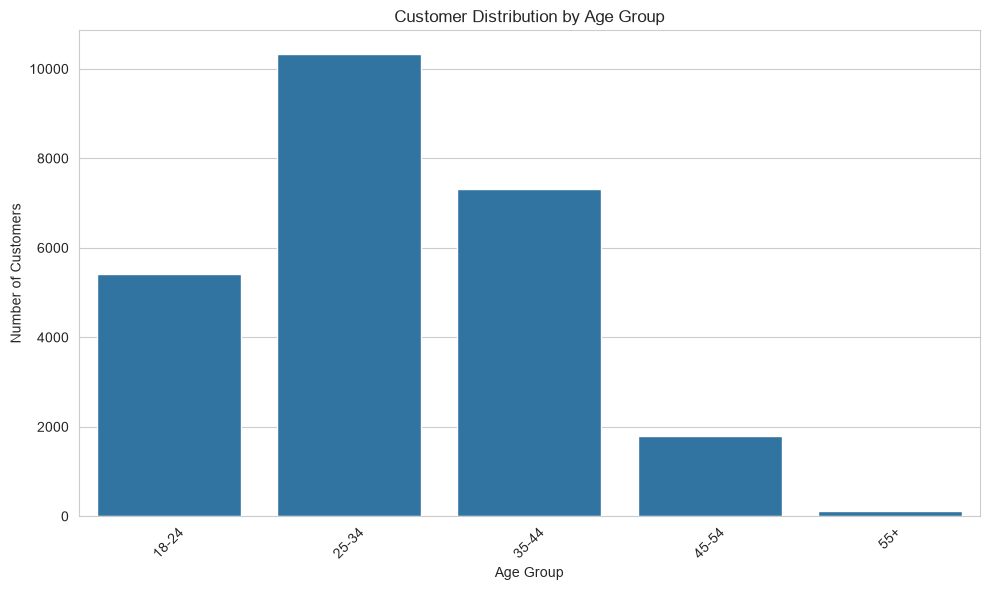

In [13]:
# Calculate customer distribution by age group
age_group_counts = customers["age_group"].value_counts().sort_index()

# Plot age-group distribution
plt.figure(figsize=(10, 6))

sns.barplot(
    x=age_group_counts.index,
    y=age_group_counts.values
)

plt.title("Customer Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Observations from Age Group Distribution

- The 25–34 age group represents the largest segment of customers.
- Customers aged 35–44 form the second-largest group.
- The 18–24 age group also contributes a considerable number of customers.
- Customer representation decreases significantly among the 45–54 and 55+ age groups.
- The distribution indicates that the customer base is primarily concentrated among individuals aged 25–44.

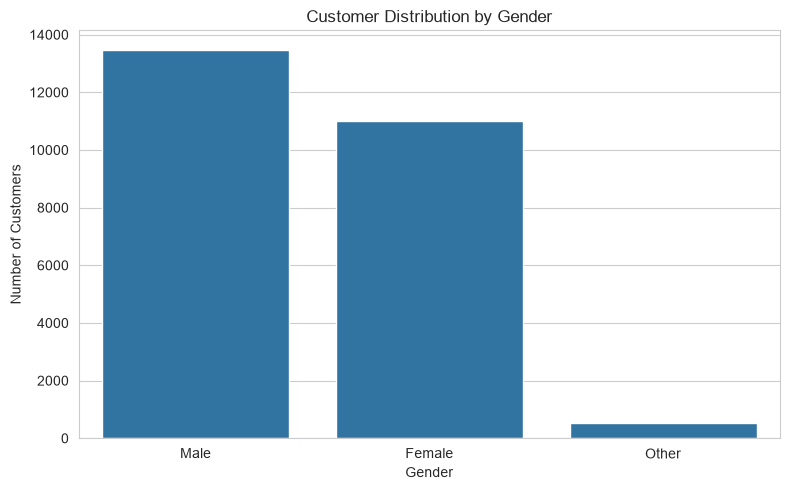

In [14]:
# Calculate customer distribution by gender
gender_counts = customers["gender"].value_counts()

# Plot gender distribution
plt.figure(figsize=(8, 5))

sns.barplot(
    x=gender_counts.index,
    y=gender_counts.values
)

plt.title("Customer Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

### Observations from Gender Distribution

- Male customers represent the largest group in the dataset.
- Female customers also account for a substantial proportion of the customer base.
- The Other category represents a comparatively small number of customers.
- The distribution indicates a relatively balanced customer presence between male and female categories, with male customers forming the majority.

## 8. Product Analysis

Product analysis is performed to identify the best-selling products and understand revenue contributions across different product categories. The top 10 products are identified based on total quantity sold, and category-wise revenue is visualised using a bar chart.

In [15]:
# Calculate total quantity sold for each product
product_sales = sales_data.groupby("product_id")["quantity"].sum().reset_index()

# Add product names
product_sales = pd.merge(
    product_sales,
    products[["product_id", "product_name"]],
    on="product_id",
    how="left"
)

# Sort products by quantity sold
top_10_products = product_sales.sort_values(
    by="quantity",
    ascending=False
).head(10)

# Display the top 10 products
display(top_10_products)

,product_id,quantity,product_name
403,PROD10403,14178,Chanda Deluxe Winter Wear
341,PROD10341,11704,"Solanki, Basic Winter Wear"
112,PROD10112,10493,Soman Classic Comic
101,PROD10101,9660,"Memon, Compact Action Figure"
392,PROD10392,8948,Gandhi-Lanka Ultra Storage & Container
31,PROD10031,8915,Shah Basic Handbag
417,PROD10417,8678,Goda Ultra Air Conditioner
203,PROD10203,8117,"Mistry, Basic Large Appliance"
488,PROD10488,7944,Kar-Issac Premium Kids Wear
246,PROD10246,7372,"Chaudhry, Advanced Smartwatche"


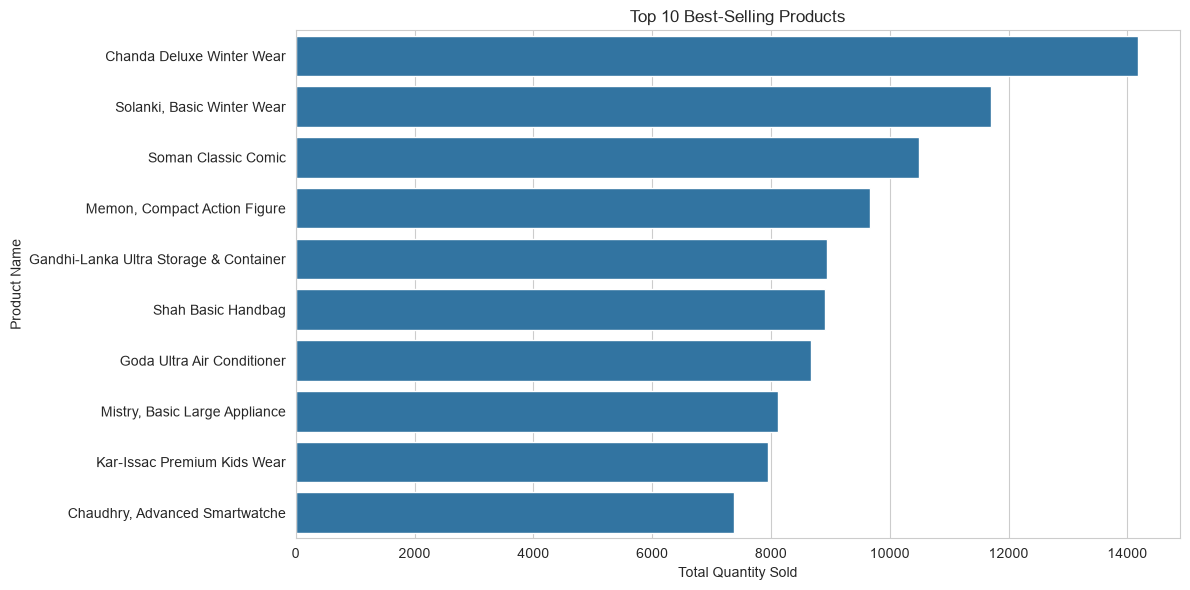

In [16]:
# Plot Top 10 Best-Selling Products
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_products,
    x="quantity",
    y="product_name"
)

plt.title("Top 10 Best-Selling Products")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product Name")
plt.tight_layout()
plt.show()

### Observations from Top 10 Best-Selling Products

- Chanda Deluxe Winter Wear is the best-selling product, with 14,178 units sold.
- Solanki, Basic Winter Wear ranks second, with 11,704 units sold.
- Soman Classic Comic ranks third, with 10,493 units sold.
- The top 10 products show considerable variation in sales quantities.
- Products from different categories, including clothing, electronics, toys, and home appliances, appear among the best-selling items.
- These products represent popular items that may require closer attention to inventory management and stock availability.

In [17]:
# Merge sales data with product categories
category_sales = pd.merge(
    sales_data,
    products[["product_id", "category"]],
    on="product_id",
    how="left"
)

# Calculate total revenue for each category
category_revenue = category_sales.groupby(
    "category"
)["item_revenue"].sum().reset_index()

# Sort categories by revenue
category_revenue = category_revenue.sort_values(
    by="item_revenue",
    ascending=False
)

# Display category-wise revenue
display(category_revenue)

,category,item_revenue
6,Electronics,9.942962e+08
0,Appliances,3.264295e+08
12,Home & Kitchen,1.279126e+08
9,Furniture,1.205464e+08
7,Fashion,1.128668e+08
8,Footwear,6.641527e+07
3,Bags,4.534071e+07
11,Health & Wellness,2.588470e+07
18,Sports,2.122822e+07
20,Toys,1.988858e+07


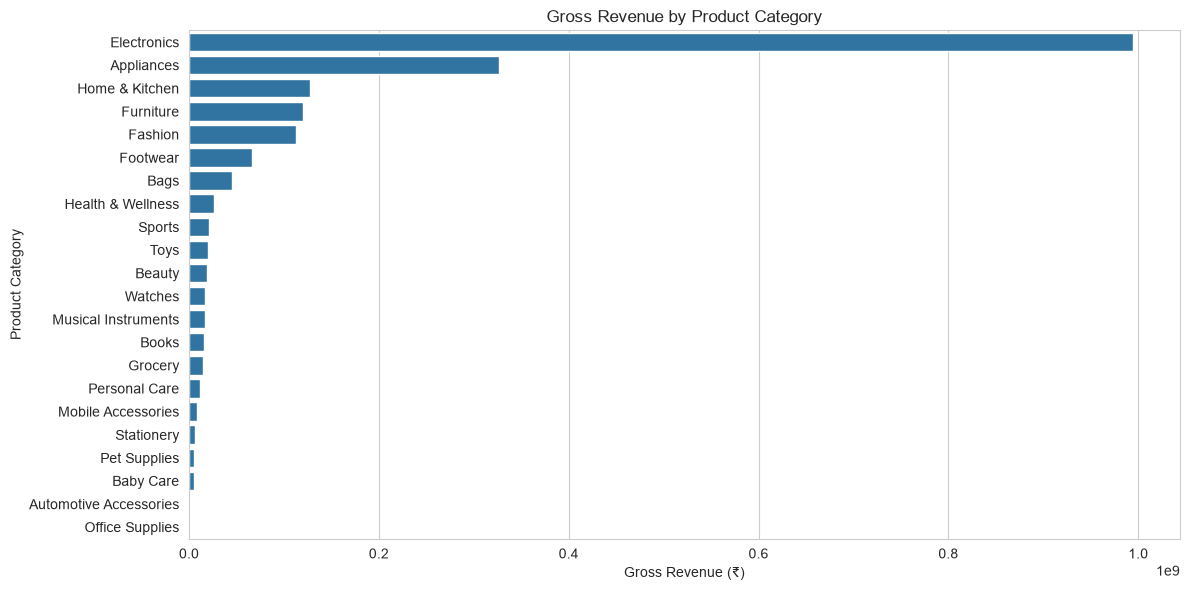

In [18]:
# Revenue by Product Category

plt.figure(figsize=(12, 6))

sns.barplot(
    data=category_revenue,
    x="item_revenue",
    y="category"
)

plt.title("Gross Revenue by Product Category")
plt.xlabel("Gross Revenue (₹)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

### Observations from Revenue by Product Category

- Electronics is the highest revenue-generating category, contributing approximately ₹99.43 crore.
- Appliances ranks second, generating approximately ₹32.64 crore in gross revenue.
- Home & Kitchen, Furniture, and Fashion are the next major revenue-generating categories.
- Electronics alone contributes approximately 50% of the total gross revenue from delivered orders.
- Electronics and Appliances together account for approximately 66.5% of the total gross revenue.
- Automotive Accessories and Office Supplies contribute the least revenue among the categories.
- The results indicate that revenue is concentrated in a few major product categories.

## 9. Correlation Analysis

Correlation analysis is used to identify relationships between numerical variables in the datasets. A correlation matrix and heatmap are used to visualise the strength and direction of relationships between numerical features.

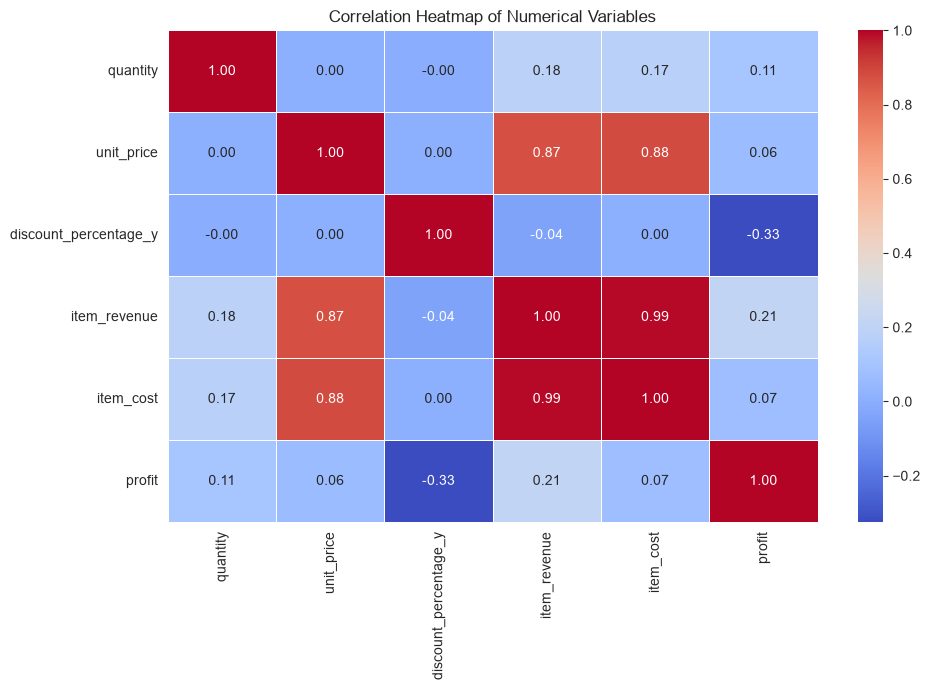

In [20]:
# Select relevant numerical columns
correlation_data = sales_data[
    ["quantity", "unit_price", "discount_percentage_y",
     "item_revenue", "item_cost", "profit"]
]

# Calculate correlation matrix
correlation_matrix = correlation_data.corr()

# Plot correlation heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

### Observations from Correlation Heatmap

- Unit price has a strong positive correlation with item revenue (0.87), indicating that higher-priced products generally contribute to higher revenue per order item.
- Item revenue and item cost have a very strong positive correlation (0.99), showing that higher-revenue items are generally associated with higher costs.
- Discount percentage has a moderate negative correlation with profit (-0.33), suggesting that higher discounts tend to be associated with lower profit.
- Quantity has a weak positive correlation with item revenue (0.18), indicating that quantity alone has a limited linear relationship with revenue.
- Unit price has a strong positive correlation with item cost (0.88).
- Overall, the heatmap highlights relationships between pricing, revenue, cost, discounts, and profitability.

## 10. Additional Visualization

Additional visualization is performed to explore further insights from the sales data. In this section, total profit is analysed across different product categories using a bar chart to identify the categories contributing the most to overall profitability.

In [21]:
# Calculate total profit by product category
category_profit = category_sales.groupby(
    "category"
)["profit"].sum().reset_index()

# Sort categories by profit
category_profit = category_profit.sort_values(
    by="profit",
    ascending=False
)

# Display category-wise profit
display(category_profit)

,category,profit
7,Fashion,37461222.13
12,Home & Kitchen,23010617.87
8,Footwear,19553630.12
3,Bags,12977026.11
0,Appliances,12656074.04
9,Furniture,11702311.62
6,Electronics,6006174.82
11,Health & Wellness,5681322.82
4,Beauty,4971292.85
18,Sports,4767846.78


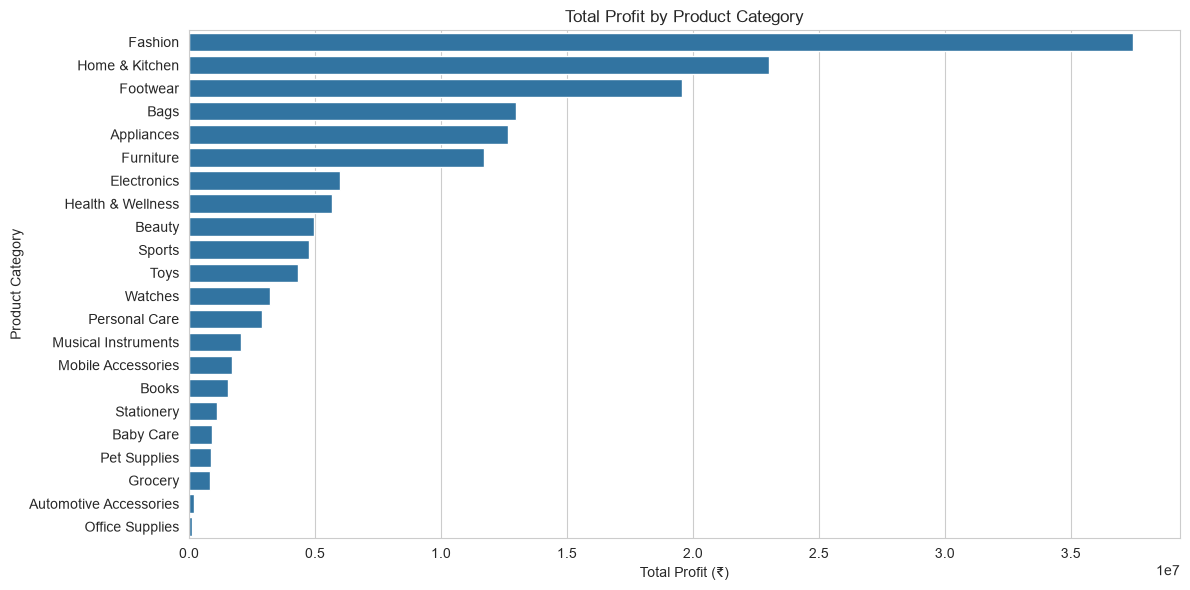

In [22]:
# Profit by Product Category

plt.figure(figsize=(12, 6))

sns.barplot(
    data=category_profit,
    x="profit",
    y="category"
)

plt.title("Total Profit by Product Category")
plt.xlabel("Total Profit (₹)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

### Observations from Profit by Product Category

- Fashion is the highest profit-generating category, contributing approximately ₹3.75 crore.
- Home & Kitchen ranks second, generating approximately ₹2.30 crore in profit.
- Footwear ranks third, with approximately ₹1.96 crore in total profit.
- Electronics, despite generating the highest revenue, ranks seventh in total profit with approximately ₹60.06 lakh.
- Appliances generates high revenue but contributes comparatively lower profit than several other categories.
- Automotive Accessories and Office Supplies contribute the least profit among the categories.
- The analysis reveals that high revenue does not necessarily result in high profitability.

## 11. Conclusion and Business Recommendations

The exploratory data analysis provided insights into sales trends, customer demographics, product performance, revenue distribution, and profitability. The analysis helped identify important patterns in the dataset and highlighted opportunities for improving business performance. Based on the findings, the following business recommendations are proposed:

### Business Recommendations

1. **Focus on High-Profit Categories:** Fashion, Home & Kitchen, and Footwear generate the highest profits. The business should prioritise these categories through targeted promotions, product expansion, and effective inventory management.

2. **Improve Electronics Profitability:** Electronics generates the highest revenue but ranks only seventh in total profit. The business should review product costs, supplier pricing, and discount strategies to improve profit margins.

3. **Target the Largest Customer Segment:** Customers aged 25–34 represent the largest age group. Businesses can develop targeted marketing campaigns, personalised offers, and product recommendations to improve customer engagement.

4. **Optimise Discount Strategies:** The correlation analysis shows a negative relationship between discount percentage and profit (-0.33). Businesses should evaluate discount levels and avoid excessive discounts that may reduce profitability.

5. **Maintain Inventory of Best-Selling Products:** The top 10 best-selling products have high sales quantities. Businesses should monitor their stock levels and plan replenishment to reduce the risk of stock shortages.

6. **Investigate Seasonal Sales Patterns:** The significant revenue increase during Q4 2025 should be investigated further. Businesses can examine seasonal demand patterns and plan inventory and promotional campaigns accordingly.

### Final Conclusion

This project successfully performed exploratory data analysis on an Indian e-commerce dataset containing customer, product, order, and order-item information. The analysis identified monthly and quarterly sales trends, customer demographic patterns, best-selling products, category-wise revenue, and profitability relationships. The visualisations revealed that Electronics generated the highest revenue, while Fashion contributed the highest total profit. These findings demonstrate the importance of analysing both revenue and profitability when making business decisions. The results provide useful insights for inventory planning, pricing strategies, customer targeting, and business performance improvement. Since the dataset is synthetic, the findings represent patterns within the provided dataset and should not be treated as conclusions about actual consumer behaviour.